- Pipeline on the pre-bleach frame: percentile normalization, Gaussian
  smoothing, CLAHE, Otsu threshold, small-object removal, hole filling,
  distance-transform watershed, removal of droplets touching the border
- Parameters chosen on 3 tiff files; 6 files held out for validation
- Grid search and visual comparison to select parameters:
  sigma=0.5, kernel_size=64, clip_limit=0.01,
  min_droplet_area=150 px, min_peak_distance=6 px
- segment_droplets() applies the full pipeline with the chosen parameters
- Summary figure showing each segmentation step per file

In [1]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage import filters, exposure, measure, morphology, segmentation
from skimage.feature import peak_local_max
from skimage.segmentation import mark_boundaries
from scipy import ndimage as ndi
from skimage.color import label2rgb

In [2]:
files = sorted(Path("data").glob("*.tif"))

# 1. Grid Search to evaluate and choose default Mask parameters

In [3]:
def normalize(img, pct=(2,98)):
    """Percentile normalization to [0, 1] (needed by CLAHE)."""
    
    low, high = np.percentile(img, pct)
    return np.clip((img - low) / (high - low), 0, 1)

In [4]:
def create_mask(normalized, s, k, cl):
    """ Gaussian smooth -> CLAHE adjustment -> Otsu threshold. 
        Input must already be normalized to [0, 1]. Outputs the mask."""

    smooth = filters.gaussian(normalized, sigma=s, preserve_range=True)
    local = exposure.equalize_adapthist(smooth, kernel_size=k, clip_limit=cl)
    local_mask = local > filters.threshold_otsu(local)
    return local_mask

In [5]:
# Tested values

s_values = [0.5, 1.0, 2.0]        # sigma: Higher values produce more smoothing and blur.
k_values = [32, 64, 128]          # kernel size: Higher values correspond to larger regions used to assess local contrast. 
cl_values = [0.005, 0.01, 0.03]   # clip limit: Higher values allow stronger contrast enhancement

In [6]:
images = {}
normalized = {}
masks = {}

for f in files:
    raw = tifffile.imread(f)
    name = f.stem
    original = raw[0].astype(np.float64)
    images[name] = original
    normalized[name] = normalize(original)     
    for s, k, cl in itertools.product(s_values, k_values, cl_values):
        masks[(name, s, k, cl)] = create_mask(normalized[name], s, k, cl)

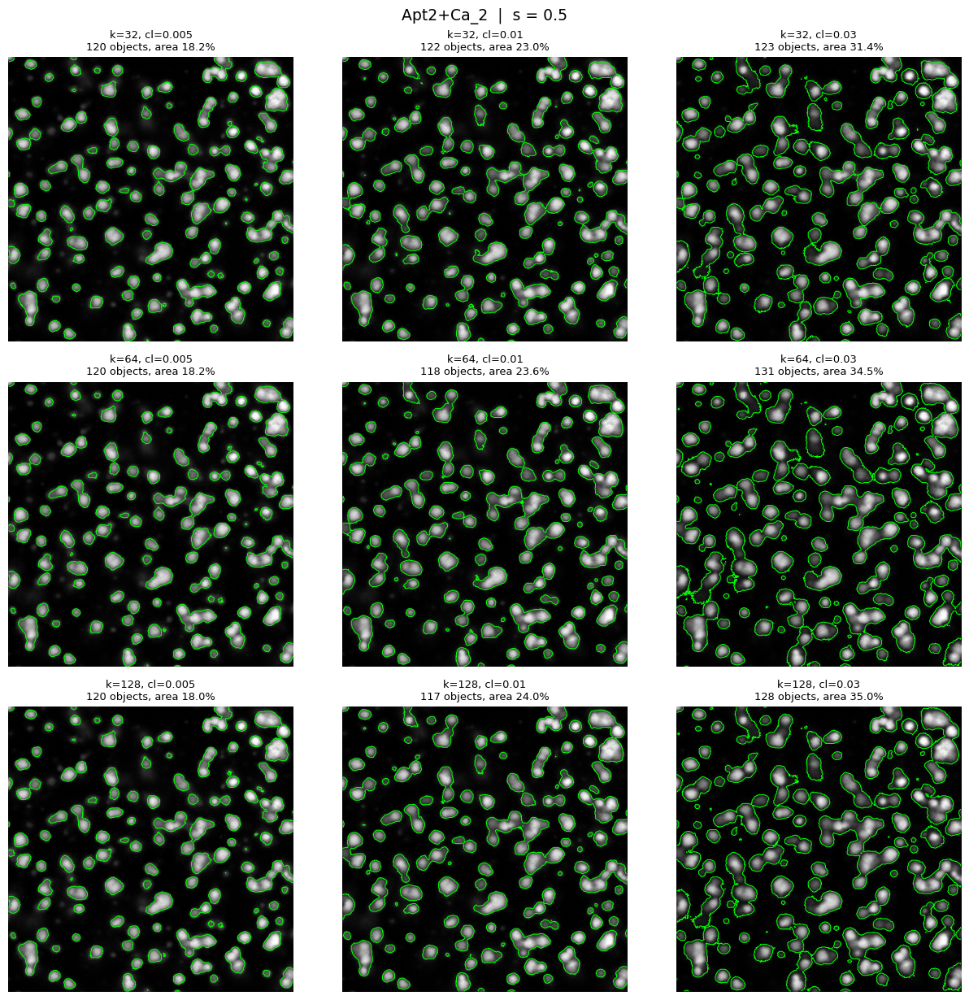

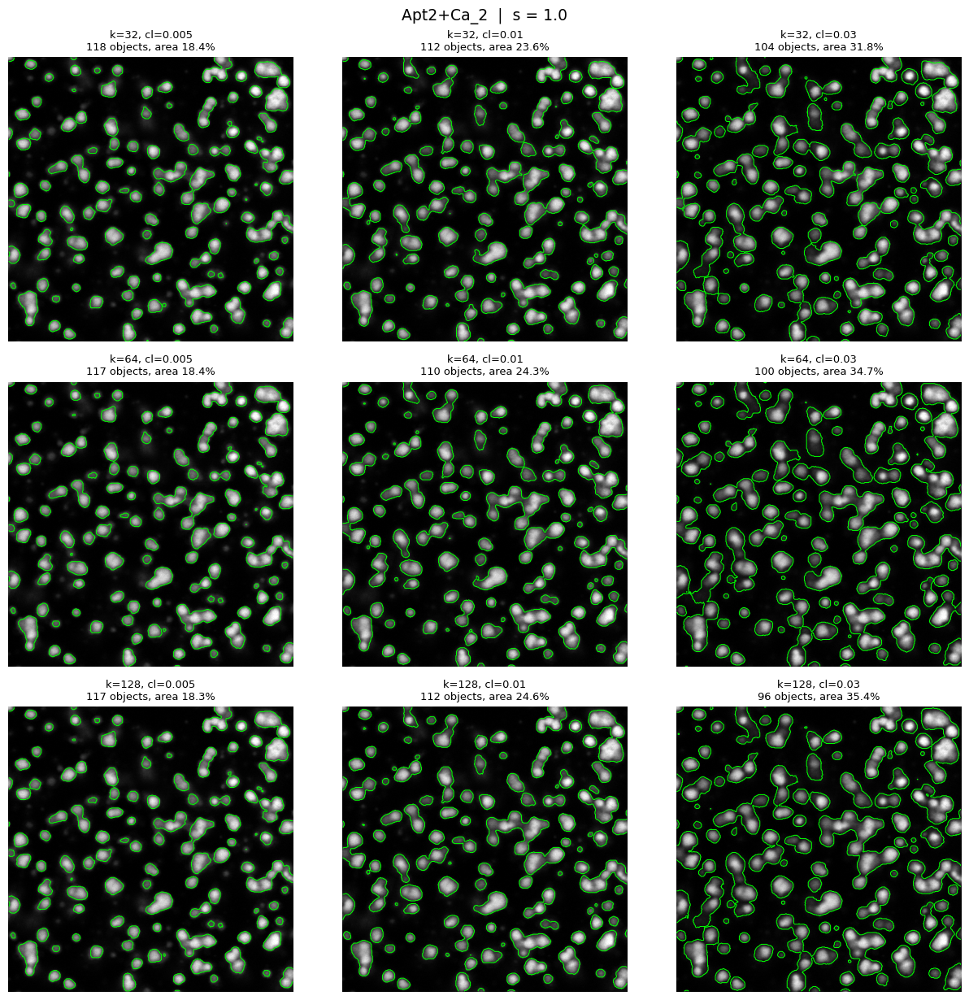

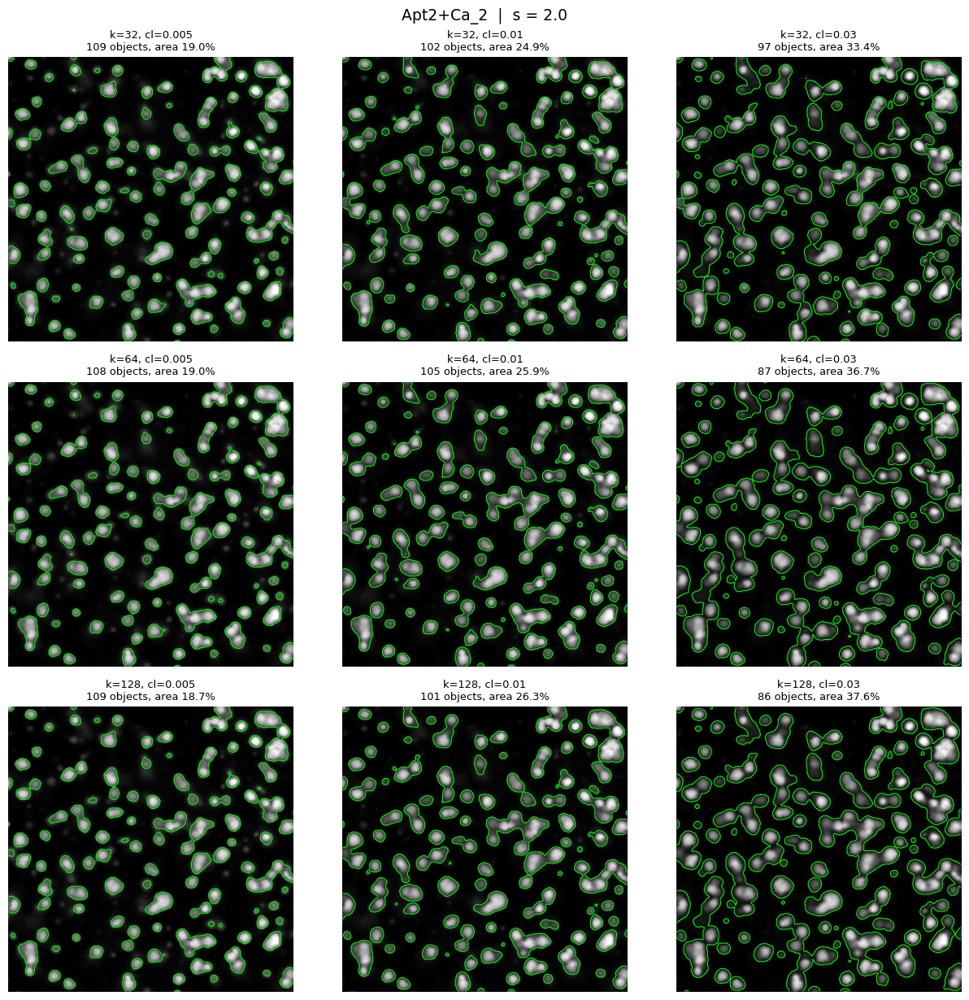

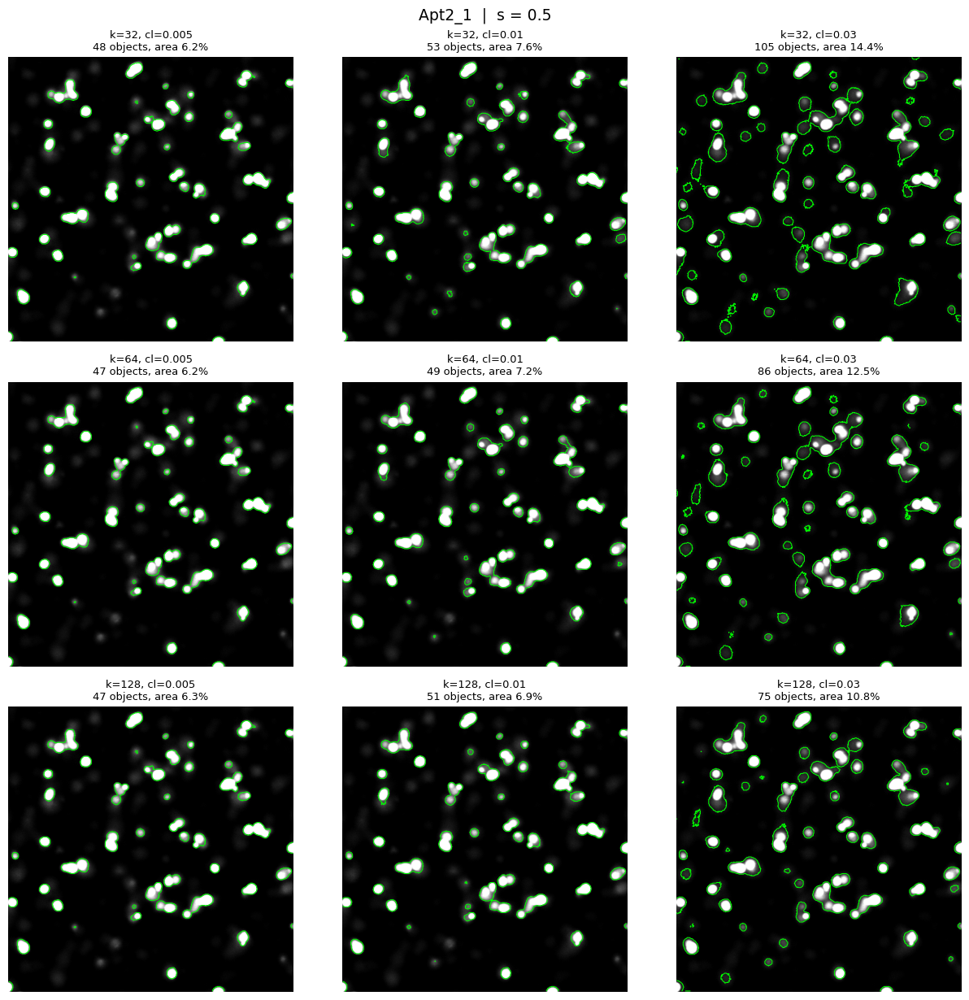

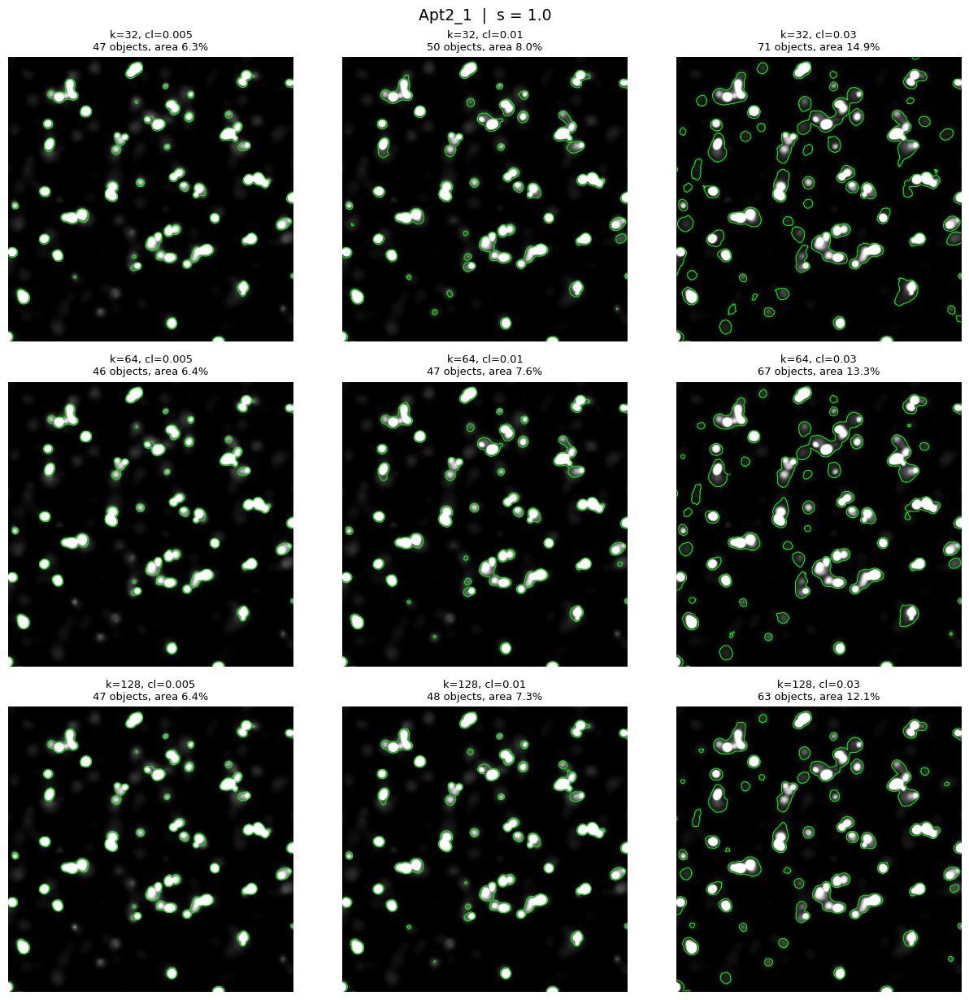

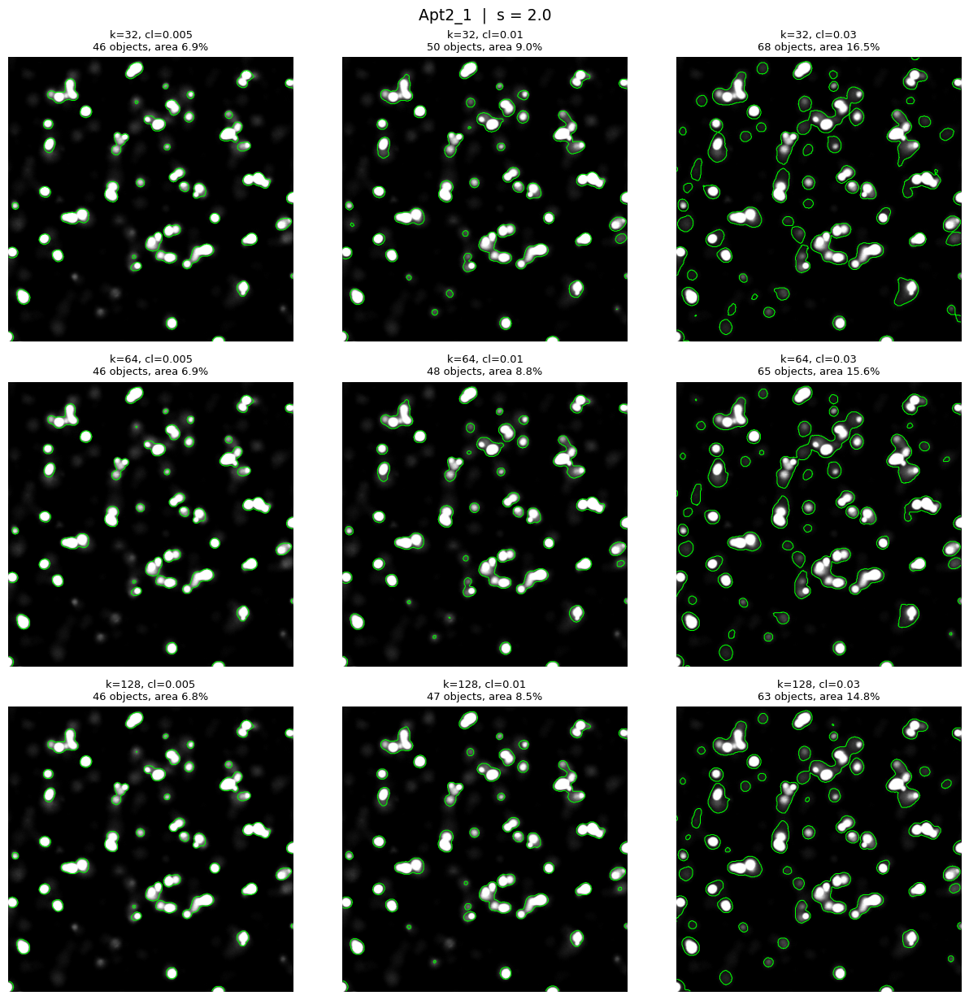

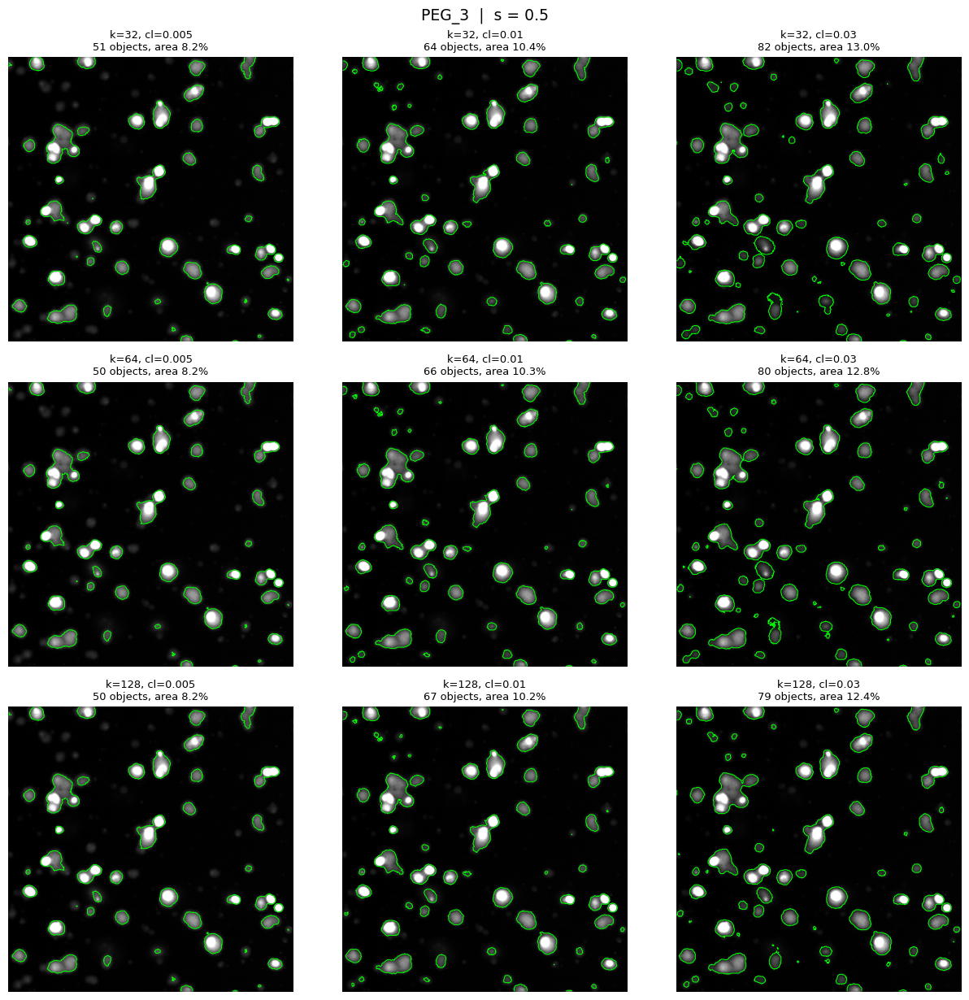

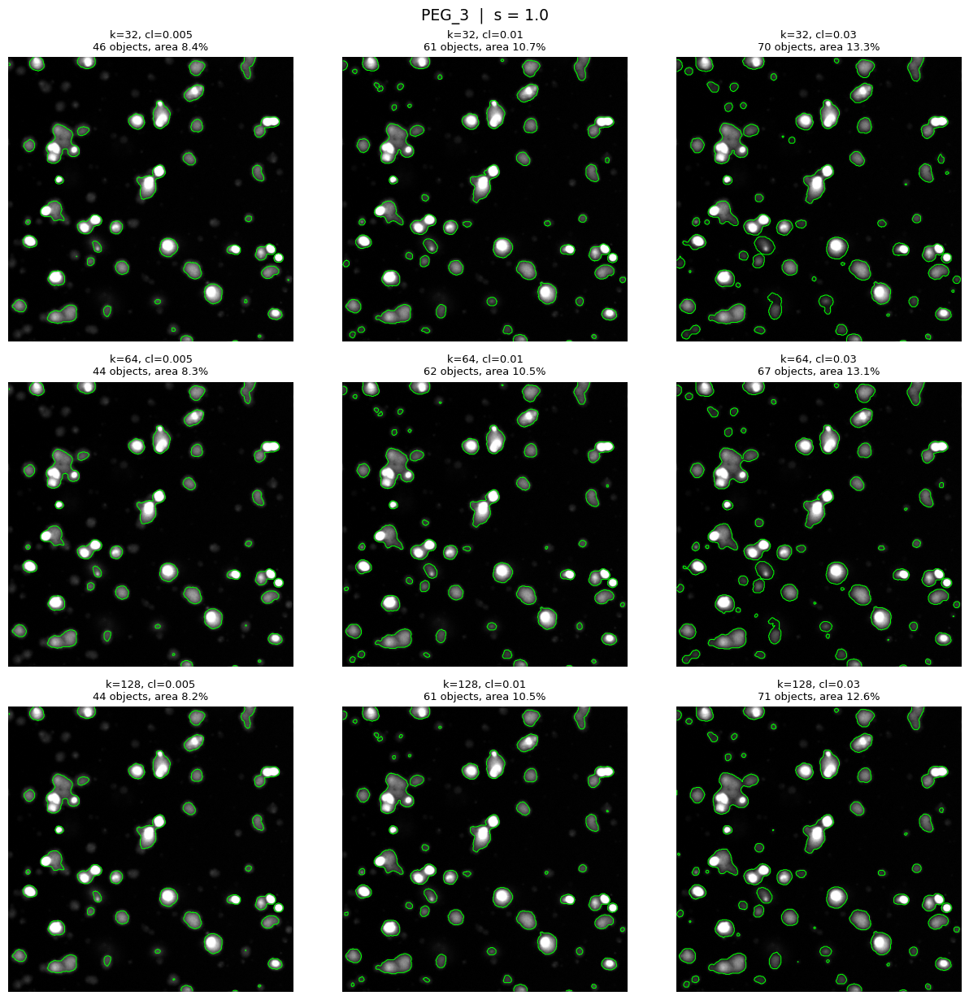

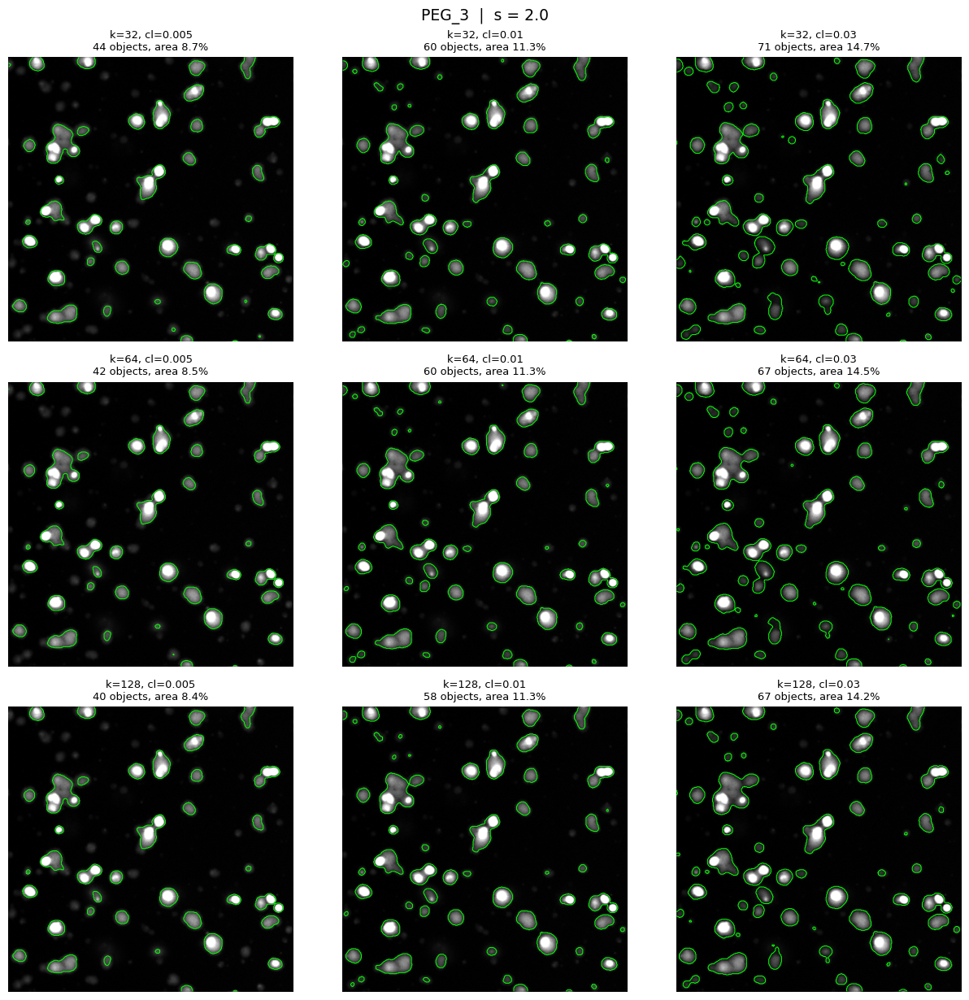

In [7]:
# A figure for each file and sigma value (rows = k: kernel size, columns = cl: clip limit)

for name, img in images.items():

    for s in s_values:
        fig, axes = plt.subplots(len(k_values), len(cl_values),
                                 figsize=(4 * len(cl_values), 4 * len(k_values)))
        for i, k in enumerate(k_values):
            for j, cl in enumerate(cl_values):
                m = masks[(name, s, k, cl)]
                n_obj = measure.label(m).max()  # number of objects found
                area = m.mean() # fraction of image covered by mask

                ax = axes[i, j]
                ax.imshow(img, cmap="gray")
                ax.contour(m.astype(float), levels=[0.5], colors="lime", linewidths=0.7)
                ax.set_title(f"k={k}, cl={cl}\n{n_obj} objects, area {area:.1%}", fontsize=9)
                ax.axis("off")

        fig.suptitle(f"{name}  |  s = {s}", fontsize=13)
        plt.tight_layout()
        #fig.savefig(out_dir / f"{name}_s{s}.png", dpi=120)
        plt.show()
 

Based on visual inspection of above figure, appropriate sigma and kernel size are chosen (**sigma** = **0.5**; **kernel size** = **64**), while clip limit is restricted at either 0.005 or 0.01, evaluated and chosen in the following steps.

# 2. Choose clip limit and minimum droplet area

In [8]:
def remove_small(mask, min_droplet_area):
    """Keep objects with at least min_droplet_area pixels, then fill any enclosed holes inside droplets."""

    clean = morphology.remove_small_objects(mask, max_size=min_droplet_area - 1, connectivity=2)
    return ndi.binary_fill_holes(clean)

In [9]:
# Fixed parameters and candidates

S = 0.5
K = 64

CL_TO_SHOW = [0.005, 0.01]      # clip limit possible values
AREA_TO_SHOW = [100, 120, 150, 200]       # min_droplet_area values to compare

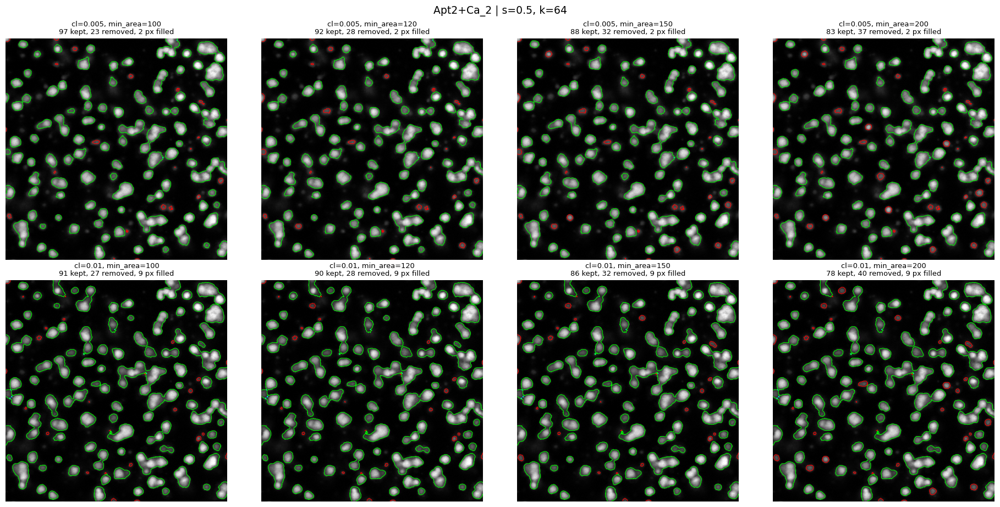

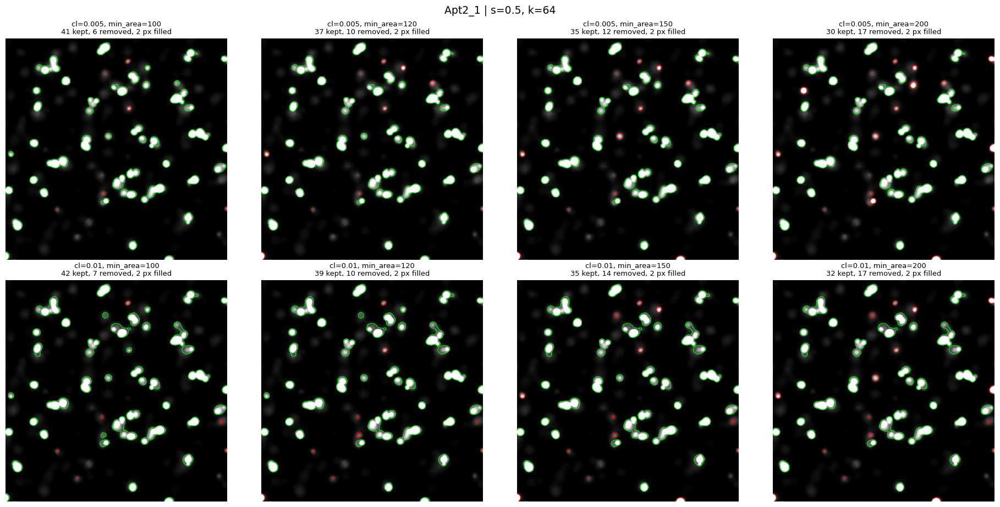

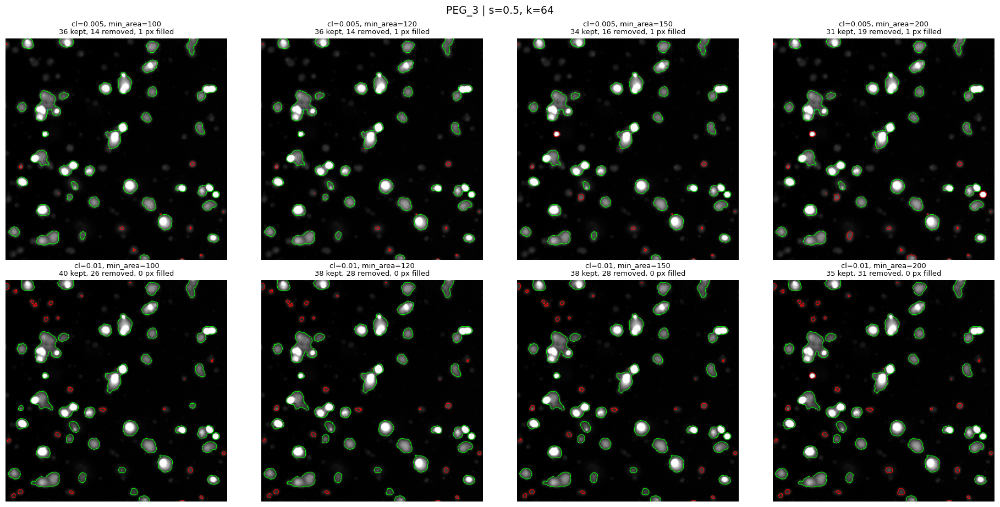

In [10]:
# green = objects kept, red = objects removed, blue = holes filled inside kept objects
 
for name, img in images.items():
    fig, axes = plt.subplots(len(CL_TO_SHOW), len(AREA_TO_SHOW), squeeze=False,
                             figsize=(4.5 * len(AREA_TO_SHOW), 4.5 * len(CL_TO_SHOW)))
    for i, cl in enumerate(CL_TO_SHOW):
        m = masks[(name, S, K, cl)]

        for j, a in enumerate(AREA_TO_SHOW):

            kept = morphology.remove_small_objects(m, max_size=a - 1, connectivity=2)
            removed = m & ~kept
            filled = ndi.binary_fill_holes(kept) & ~kept

            ax = axes[i, j]
            ax.imshow(img, cmap="gray")
            for layer, color in ((kept, "lime"), (removed, "red"), (filled, "deepskyblue")):
                 if layer.any():
                     ax.contour(layer.astype(float), levels=[0.5], colors=color, linewidths=0.7)

            n_kept = measure.label(kept, connectivity=2).max()
            n_removed = measure.label(removed, connectivity=2).max()
            ax.set_title(f"cl={cl}, min_area={a}\n{n_kept} kept, {n_removed} removed, "
                         f"{filled.sum()} px filled", fontsize=9)
            ax.axis("off")

    fig.suptitle(f"{name} | s={S}, k={K}", fontsize=13)
    plt.tight_layout()
    plt.show()

Based on visual inspection of above figure, appropriate clip limit and minimum droplet area are chosen (**clip limit** = **0.01**; **minimum droplet area** = **150**).

# 3. Watershed on the chosen mask

In [11]:
# Chosen after the visual comparisons shown above

S, K, CL = 0.5, 64, 0.01
chosen_masks = {name: masks[(name, S, K, CL)] for name in images}

MIN_DROPLET_AREA = 150
clean_masks = {name: remove_small(m, MIN_DROPLET_AREA) for name, m in chosen_masks.items()}

In [12]:
def watershed_seeds(clean_mask, min_peak_distance):
    """Distance map and watershed seeds (row, column) for a cleaned mask."""

    distance = ndi.distance_transform_edt(clean_mask)
    components = measure.label(clean_mask, connectivity=2)
    peaks = peak_local_max(distance, min_distance=min_peak_distance,
                           labels=components, exclude_border=False)
    return distance, peaks

def split_touching(clean_mask, min_peak_distance, min_droplet_area):
    """Distance-transform watershed, then removal of fragments smaller than min_droplet_area."""
    
    distance, peaks = watershed_seeds(clean_mask, min_peak_distance)
    markers = np.zeros(clean_mask.shape, dtype=np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    labels = segmentation.watershed(-distance, markers=markers, mask=clean_mask, connectivity=2)
    labels = morphology.remove_small_objects(labels, max_size=min_droplet_area - 1)
    labels, _, _ = segmentation.relabel_sequential(labels)
    return labels

In [13]:
def shape_table(labels):
    """Area, equivalent radius, solidity and circularity (1 = perfect circle) of every object."""
    props = pd.DataFrame(measure.regionprops_table(
        labels, properties=("label", "area", "perimeter", "solidity")))
    props["radius"] = np.sqrt(props["area"] / np.pi)
    props["circularity"] = 4 * np.pi * props["area"] / np.maximum(props["perimeter"], 1) ** 2
    return props

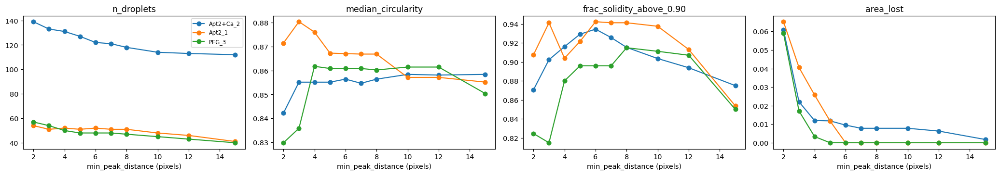

file               Apt2+Ca_2  Apt2_1  PEG_3
min_peak_distance                          
2                      139.0    54.0   57.0
3                      133.0    51.0   54.0
4                      131.0    52.0   50.0
5                      127.0    51.0   48.0
6                      122.0    52.0   48.0
7                      121.0    51.0   48.0
8                      118.0    51.0   47.0
10                     114.0    48.0   45.0
12                     113.0    46.0   43.0
15                     112.0    41.0   40.0


In [ ]:
# various metrics to evalutae the appropriate minimum peak distance

# n_droplets: rises if droplets are over-split, drops if touching droplets are merged.
# median_circularity: a droplet cut in half has circularity ~0.75.
# frac_solidity_above_0.90: merged pairs have low solidity.
# area_lost: fraction of the mask removed because the watershed produced fragments.

PEAK_DISTANCES = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15]
 
sweep = []
for name, cm in clean_masks.items():
    for d in PEAK_DISTANCES:
        labels = split_touching(cm, d, MIN_DROPLET_AREA)
        props = shape_table(labels)
        sweep.append({"file": name, "min_peak_distance": d, "n_droplets": len(props),
                      "median_circularity": props["circularity"].median(),
                      "frac_solidity_above_0.90": (props["solidity"] > 0.9).mean(),
                      "area_lost": 1 - (labels > 0).sum() / cm.sum()})
sweep = pd.DataFrame(sweep)
 
metrics = ["n_droplets", "median_circularity", "frac_solidity_above_0.90", "area_lost"]
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.6))
for name, df in sweep.groupby("file"):
    for ax, col in zip(axes, metrics):
        ax.plot(df["min_peak_distance"], df[col], "o-", label=name)
for ax, col in zip(axes, metrics):
    ax.set_title(col); ax.set_xlabel("min_peak_distance (pixels)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
 
print(sweep.pivot_table(index="min_peak_distance", columns="file", values="n_droplets").to_string())

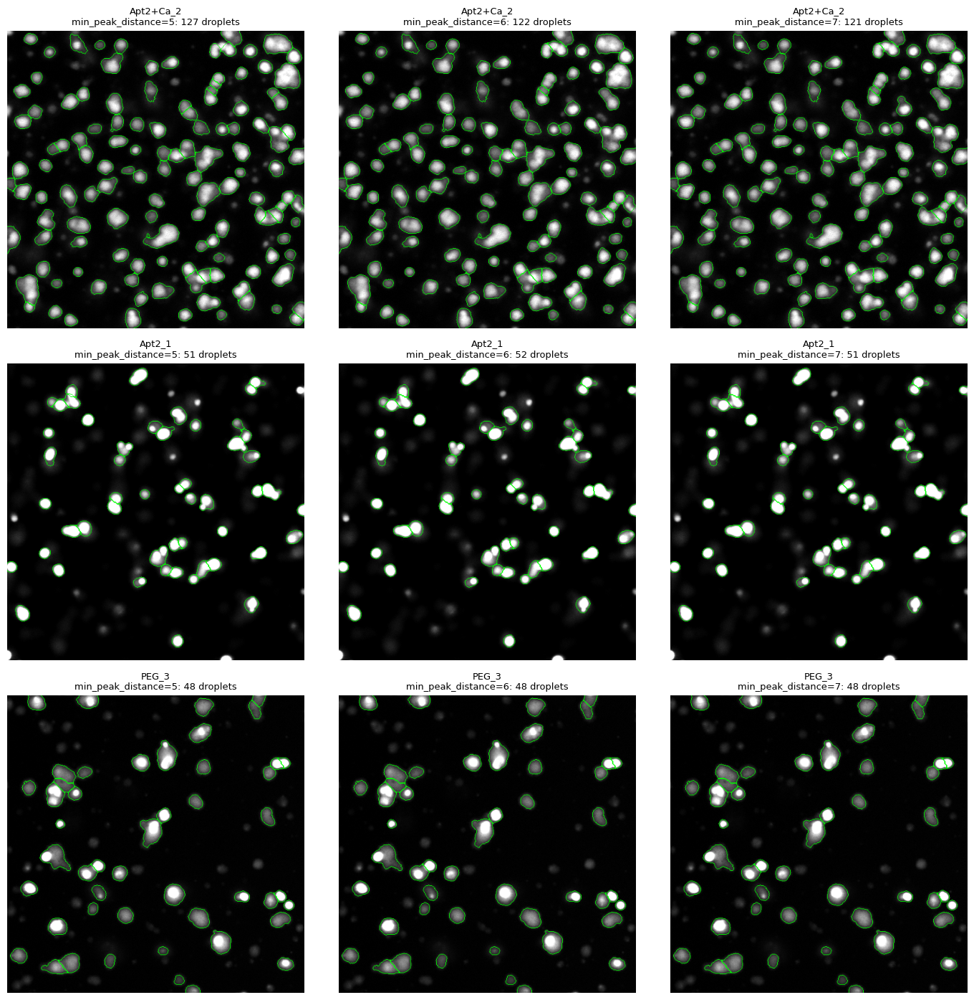

In [15]:
PEAK_TO_SHOW = [5, 6, 7]
CROP = None      # e.g. (slice(100, 300), slice(150, 350)) = rows 100-300, columns 150-350

view = (slice(None), slice(None)) if CROP is None else CROP
fig, axes = plt.subplots(len(clean_masks), len(PEAK_TO_SHOW), squeeze=False,
                         figsize=(4.5 * len(PEAK_TO_SHOW), 4.5 * len(clean_masks)))
for i, (name, cm) in enumerate(clean_masks.items()):
    img = images[name]
    lo, hi = np.percentile(img, (1, 99.5))
    display = np.clip((img - lo) / (hi - lo), 0, 1)    # scale to [0, 1], needed for the image display with mark_boundaries
    for j, d in enumerate(PEAK_TO_SHOW):
        labels = split_touching(cm, d, MIN_DROPLET_AREA)
        ax = axes[i, j]
        ax.imshow(mark_boundaries(display[view], labels[view], color=(0, 1, 0)))
        ax.set_title(f"{name}\nmin_peak_distance={d}: {labels.max()} droplets", fontsize=9)
        ax.axis("off")
plt.tight_layout(); plt.show()

Based on visual inspection of above figure, appropriate minimum peak distance is chosen (**minimum peak distance** = **6**).

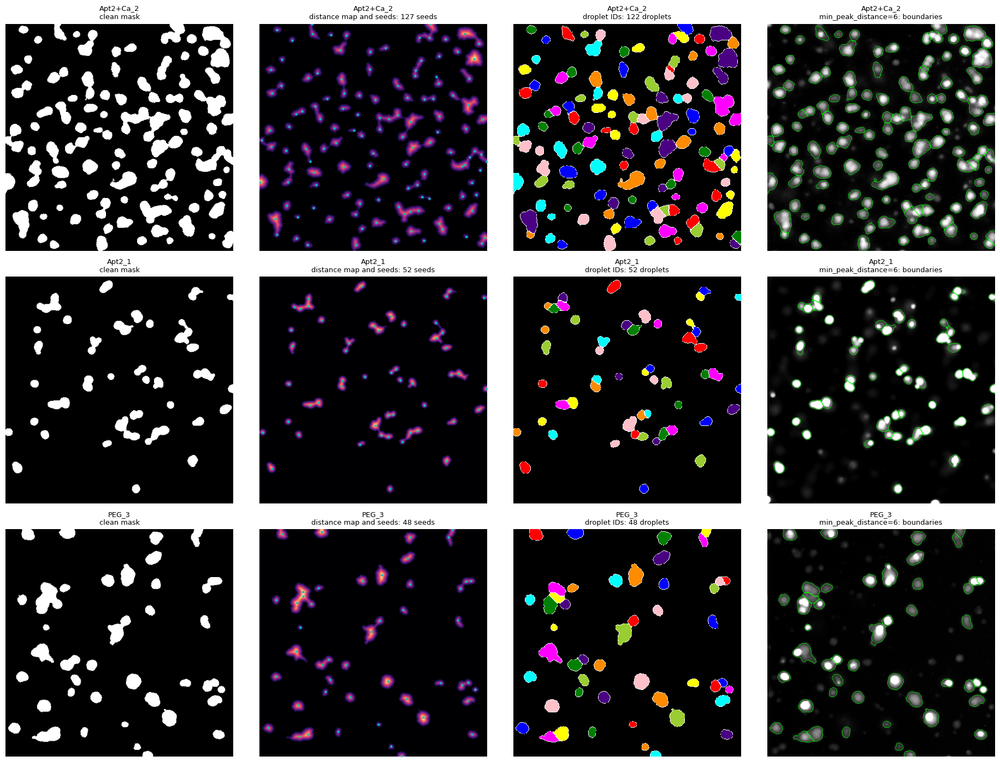

In [16]:
D = 6            # selected min_peak_distance
CROP = None      # e.g. (slice(100, 300), slice(150, 350)) = rows 100-300, columns 150-350

view = (slice(None), slice(None)) if CROP is None else CROP
fig, axes = plt.subplots(len(clean_masks), 4, squeeze=False,
                         figsize=(4.5 * 4, 4.5 * len(clean_masks)))

for i, (name, cm) in enumerate(clean_masks.items()):
    img = images[name]
    lo, hi = np.percentile(img, (1, 99.5))
    display = np.clip((img - lo) / (hi - lo), 0, 1)    # scale to [0, 1], needed for the image display with mark_boundaries

    distance, peaks = watershed_seeds(cm, D)
    labels = split_touching(cm, D, MIN_DROPLET_AREA)

    seeds = np.zeros(cm.shape, dtype=bool)              # seeds as an image, so they can be cropped like the others
    seeds[tuple(peaks.T)] = True
    seed_rows, seed_cols = np.nonzero(seeds[view])

    axes[i, 0].imshow(cm[view], cmap="gray")
    axes[i, 0].set_title(f"{name}\nclean mask", fontsize=9)

    axes[i, 1].imshow(distance[view], cmap="magma")
    axes[i, 1].plot(seed_cols, seed_rows, "c.", markersize=4)
    axes[i, 1].set_title(f"{name}\ndistance map and seeds: {len(peaks)} seeds", fontsize=9)

    ids_rgb = label2rgb(labels[view], bg_label=0)                      # distinct colors; background black
    ids_rgb = mark_boundaries(ids_rgb, labels[view], color=(1, 1, 1))  # white line between touching droplets
    axes[i, 2].imshow(ids_rgb, interpolation="nearest")
    axes[i, 2].set_title(f"{name}\ndroplet IDs: {labels.max()} droplets", fontsize=9)

    axes[i, 3].imshow(mark_boundaries(display[view], labels[view], color=(0, 1, 0)))
    axes[i, 3].set_title(f"{name}\nmin_peak_distance={D}: boundaries", fontsize=9)

    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout(); plt.show()

# 4. Summary

In [ ]:
# choosen parameters
 
S = 0.5
K = 64
CL = 0.01
MIN_DROPLET_AREA = 150
MIN_PEAK_DISTANCE = 6

In [ ]:
def segment_droplets(frame, s=S, k=K, cl=CL, min_droplet_area=MIN_DROPLET_AREA,
                     min_peak_distance=MIN_PEAK_DISTANCE):
    """Full pipeline: normalize -> mask -> remove small objects -> watershed -> drop border droplets."""

    mask = create_mask(normalize(frame.astype(np.float64)), s, k, cl)
    labels = split_touching(remove_small(mask, min_droplet_area), min_peak_distance, min_droplet_area)
    labels = segmentation.clear_border(labels)    # remove droplets on the border
    labels, _, _ = segmentation.relabel_sequential(labels)
    return labels

In [19]:
droplet_labels = {name: segment_droplets(img) for name, img in images.items()}
for name, lab in droplet_labels.items():
    print(f"{name}: {lab.max()} droplets")

Apt2+Ca_2: 115 droplets
Apt2_1: 49 droplets
PEG_3: 44 droplets


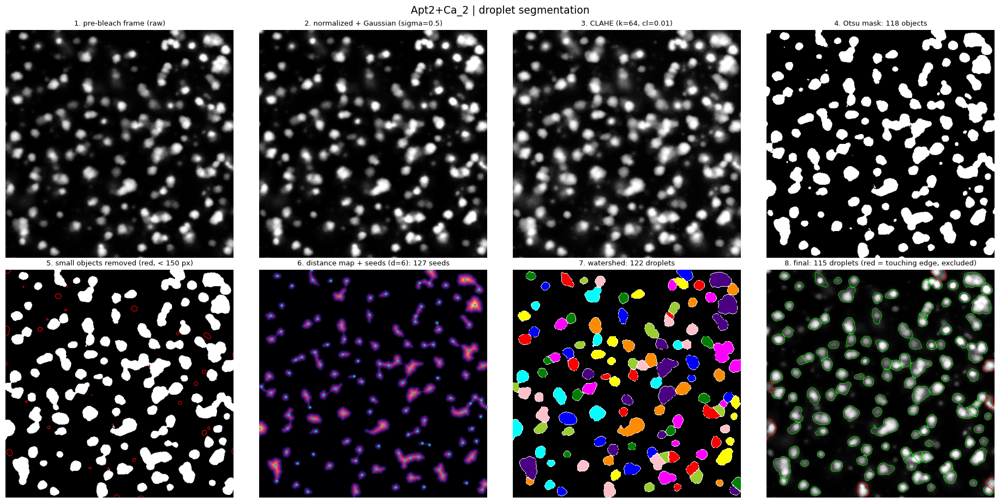

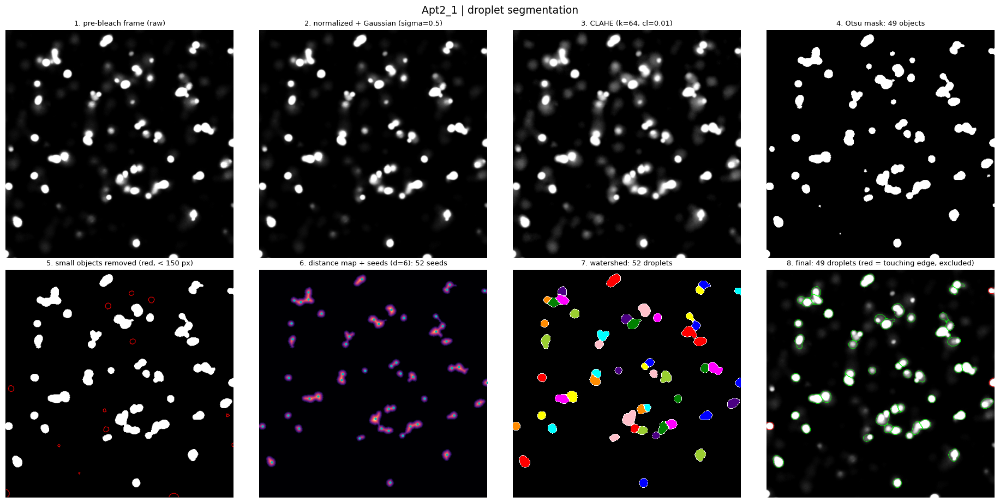

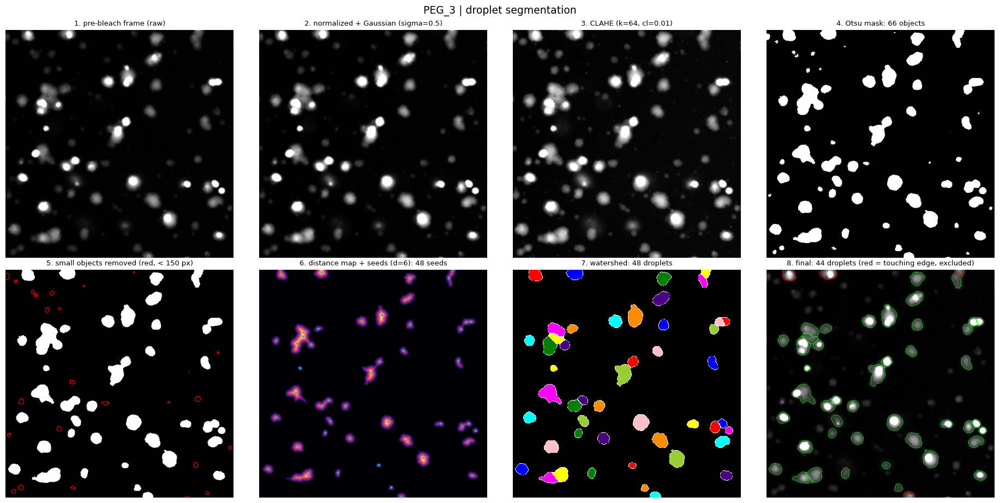

In [ ]:
# every step of the droplet segmentation, one figure per file

# (S, K, CL, MIN_DROPLET_AREA, MIN_PEAK_DISTANCE) and the functions defined above.

CROP = None          # e.g. (slice(100, 300), slice(150, 350)) to zoom; None = whole image
SAVE_DIR = None

def pipeline_steps(frame):
    """Recompute every intermediate image of segment_droplets, for display."""
    steps = {}
    steps["raw"] = frame
    steps["smooth"] = filters.gaussian(normalize(frame), sigma=S, preserve_range=True)
    steps["clahe"] = exposure.equalize_adapthist(steps["smooth"], kernel_size=K, clip_limit=CL)
    steps["otsu"] = steps["clahe"] > filters.threshold_otsu(steps["clahe"])
    steps["clean"] = remove_small(steps["otsu"], MIN_DROPLET_AREA)
    steps["distance"], steps["peaks"] = watershed_seeds(steps["clean"], MIN_PEAK_DISTANCE)
    steps["watershed"] = split_touching(steps["clean"], MIN_PEAK_DISTANCE, MIN_DROPLET_AREA)
    final = segmentation.clear_border(steps["watershed"])
    steps["final"], _, _ = segmentation.relabel_sequential(final)
    return steps


view = (slice(None), slice(None)) if CROP is None else CROP
if SAVE_DIR is not None:
    SAVE_DIR.mkdir(exist_ok=True)

for name, img in images.items():
    st = pipeline_steps(img)
    # safety check: the figure must show exactly what segment_droplets produces
    assert np.array_equal(st["final"], segment_droplets(img)), "summary differs from segment_droplets"

    lo, hi = np.percentile(img, (1, 99.5))
    display = np.clip((img - lo) / (hi - lo), 0, 1)    # scale to [0, 1], needed for mark_boundaries

    removed_small = st["otsu"] & ~st["clean"]          # objects below MIN_DROPLET_AREA
    border = (st["watershed"] > 0) & (st["final"] == 0)  # droplets dropped because they touch the edge
    seeds = np.zeros(img.shape, dtype=bool)
    seeds[tuple(st["peaks"].T)] = True
    seed_rows, seed_cols = np.nonzero(seeds[view])

    fig, axes = plt.subplots(2, 4, figsize=(4.5 * 4, 4.5 * 2))
    ax = axes.ravel()

    ax[0].imshow(img[view], cmap="gray", vmin=lo, vmax=hi)
    ax[0].set_title("1. pre-bleach frame (raw)", fontsize=9)

    ax[1].imshow(st["smooth"][view], cmap="gray")
    ax[1].set_title(f"2. normalized + Gaussian (sigma={S})", fontsize=9)

    ax[2].imshow(st["clahe"][view], cmap="gray")
    ax[2].set_title(f"3. CLAHE (k={K}, cl={CL})", fontsize=9)

    ax[3].imshow(st["otsu"][view], cmap="gray")
    ax[3].set_title(f"4. Otsu mask: {measure.label(st['otsu'], connectivity=2).max()} objects", fontsize=9)

    ax[4].imshow(st["clean"][view], cmap="gray")
    if removed_small[view].any():
        ax[4].contour(removed_small[view].astype(float), levels=[0.5], colors="red", linewidths=0.7)
    ax[4].set_title(f"5. small objects removed (red, < {MIN_DROPLET_AREA} px)", fontsize=9)

    ax[5].imshow(st["distance"][view], cmap="magma")
    ax[5].plot(seed_cols, seed_rows, "c.", markersize=4)
    ax[5].set_title(f"6. distance map + seeds (d={MIN_PEAK_DISTANCE}): {len(st['peaks'])} seeds", fontsize=9)

    ids_rgb = label2rgb(st["watershed"][view], bg_label=0)
    ids_rgb = mark_boundaries(ids_rgb, st["watershed"][view], color=(1, 1, 1))
    ax[6].imshow(ids_rgb, interpolation="nearest")
    ax[6].set_title(f"7. watershed: {st['watershed'].max()} droplets", fontsize=9)

    ax[7].imshow(mark_boundaries(display[view], st["final"][view], color=(0, 1, 0)))
    if border[view].any():
        ax[7].contour(border[view].astype(float), levels=[0.5], colors="red", linewidths=0.7)
    ax[7].set_title(f"8. final: {st['final'].max()} droplets (red = touching edge, excluded)", fontsize=9)

    for a in ax:
        a.axis("off")
    fig.suptitle(f"{name} | droplet segmentation", fontsize=13)
    plt.tight_layout()
    if SAVE_DIR is not None:
        fig.savefig(SAVE_DIR / f"{name}_segmentation_summary.png", dpi=150, bbox_inches="tight")
    plt.show()